# Slow and fast fluctuations of the pupil: the timescale model

**Experimental.** The API may change.

The pupil size fluctuates on many time scales at once: fast responses and hippus within a second, and slower changes over tens of seconds and minutes that are often called the tonic or baseline pupil size. `pp.TimescaleModel` describes a recording as a sum of such parts:

$$ y_t = \mu_s + f(t) + \sum_{k=1}^{K} a_k(t) + \varepsilon_t $$

- $y_t$ is the pupil size in log-%, $100 \log(\text{pupil}/\text{median})$, at about 20 Hz
- $\mu_s$ is the mean of segment $s$ of the recording (e.g., a block)
- $f$ is one **fast component** with a free standard deviation and time scale (typically 0.3–1 s)
- $a_k$ are **slow components ("atoms") at fixed time scales** (3, 10, 30, 100 and 300 s by default); their variances are estimated
- $\varepsilon_t$ is white measurement noise

All components are Matérn-3/2 processes (smooth random functions with one time scale each). "Which slow components does this participant have" is then the question "how much variance is there at each time scale". The model is fitted with a Kalman filter, which handles missing data exactly: blinks and artifacts are simply not observed, nothing is interpolated before the fit.

What you get from a fitted model:

- how much the pupil varies at each time scale
- the slow part of the signal (the baseline) with its uncertainty
- the signal reconstructed where it is missing, for the whole recording in one go
- checks whether the model describes the data

This notebook goes through these steps on an example recording.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypillometry as pp
from pypillometry import u

pp.logging_set_level("WARNING")
pp.set_default_inplace(False)   # methods return changed copies

## Data: mask the blinks first

The model uses every sample that is not masked, so blinks and artifacts have to be detected before. Check the detection for your data: the default velocity thresholds of `blinks_detect()` are in pupil units per ms and do not suit every eye tracker and participant (see the notebook on blink preprocessing and `d.plot.plot_blinks()`). For the slow components, the exact borders of a blink do not matter: the model leaves out 100 ms before and 200 ms after every masked stretch anyway (argument `margin`), so that no part of the blink transients stays in the data.

In [2]:
d = pp.get_example_data("rlmw_002").pupil.blinks_detect()
pd.DataFrame(d.blink_stats(units="ms")).T[["n", "mean", "max"]]

,n,mean,max
left_pupil,264,202.295455,514.0
right_pupil,250,166.008,476.0


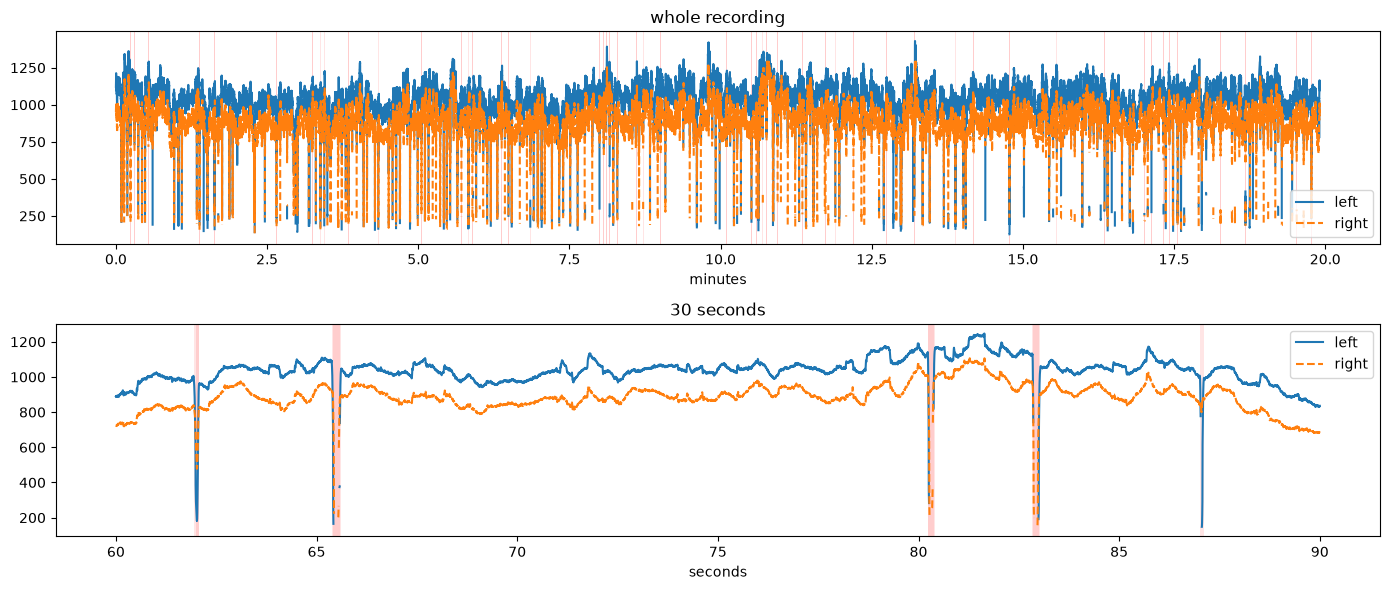

In [3]:
fig, axs = plt.subplots(2, 1, figsize=(14, 6))
d.plot.plot_pupil(ax=axs[0], units="min", show_events=False, title="whole recording")
d.plot.plot_pupil(ax=axs[1], plot_range=(60, 90) * u.sec, show_events=False, title="30 seconds")
fig.tight_layout()

## A first look: the spectrum

`d.pupil.spectrum()` computes the power spectrum without interpolating the gaps (windows with many masked samples are skipped) and `d.plot.plot_pupil_spectrum()` plots it. On logarithmic axes the spectrum is close to a straight line (about $1/f$) below 0.5 Hz and falls steeply above 1 Hz. There is no single slow time scale; the slow part is a continuum. This is why the model uses a bank of time scales. The narrow peaks are responses that are locked to the rhythm of the trials.

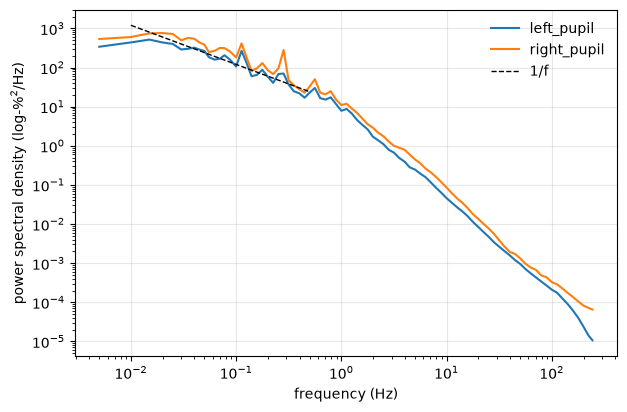

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
d.plot.plot_pupil_spectrum(ax=ax, window="200 s")
f = np.array([0.01, 0.5])
ax.plot(f, 12 / f, "k--", lw=1, label="1/f")
ax.legend(frameon=False);

In [5]:
sp = d.pupil.spectrum(window="200 s", scale="log%")["left_pupil"]
print(f"{sp.nwindows} windows of {sp.window / 1000:g} s, frequencies {sp.freqs[0]:g} to {sp.freqs[-1]:g} Hz")

10 windows of 200 s, frequencies 0.005 to 250 Hz


## Building and fitting the model

The model object is created from the `EyeData` object. The constructor prepares the data and keeps the bookkeeping that is needed to get back to the original samples later:

1. unusable samples (mask policy of the data, plus the margin) are left out
2. the signal is reduced to 20 Hz by means of the valid samples in blocks of 50 ms (a block is used if at least half of its samples are valid)
3. it is converted to log-%
4. it is cut into segments with a mean each (here one segment; see below)

In [6]:
m = pp.TimescaleModel(d, eyes="left")
m

TimescaleModel('rlmw_002', eyes=['left'], timescales=(3s, 10s, 30s, 100s, 300s), 1 segment(s), 19.9 min at 20 Hz, valid: left 89%; not fitted)

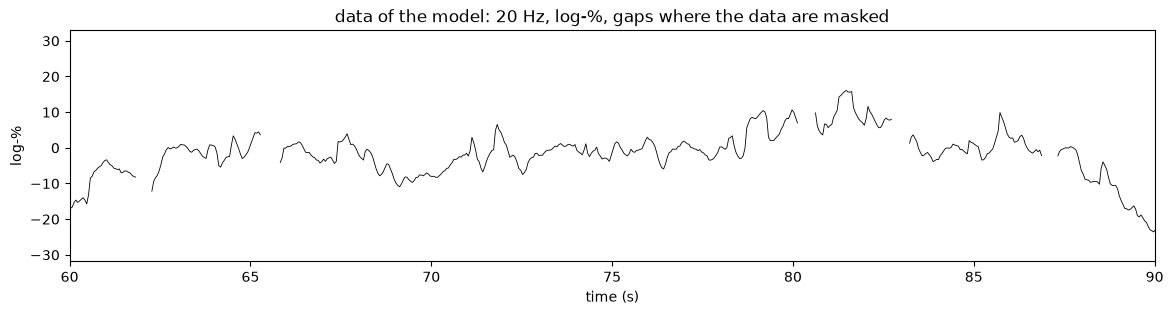

In [7]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(m.time / 1000, m.y["left"], lw=0.6, color="k")
ax.set(xlim=(60, 90), xlabel="time (s)", ylabel="log-%", title="data of the model: 20 Hz, log-%, gaps where the data are masked");

`fit()` estimates the parameters (about ten seconds for 20 minutes of data; the likelihood is evaluated in parallel threads, `n_jobs=` sets their number, and with the logging level "INFO" a progress bar shows the iterations). By default it uses a general prior of medium strength (more on priors below).

In [8]:
%time m.fit()
m.summary().T

CPU times: user 41.3 s, sys: 490 ms, total: 41.8 s
Wall time: 11.9 s


,left
fast_sd,4.840200
fast_ell,312.788098
noise_sd,0.314007
sd_3s,6.221740
sd_10s,1.237606
sd_30s,1.148202
sd_100s,2.088032
sd_300s,1.091348
slow_sd,2.898439
n_obs,21285.000000


The fast component of this recording has a standard deviation of `fast_sd` log-% (roughly percent of the pupil size) and a time scale `fast_ell` in ms. `sd_3s` ... `sd_300s` are the standard deviations of the atoms and `slow_sd` is the total standard deviation of all atoms from 10 s on. `loglik` is the restricted log-likelihood (the means are integrated out), `aic` and `bic` are computed from it.

## What the model found

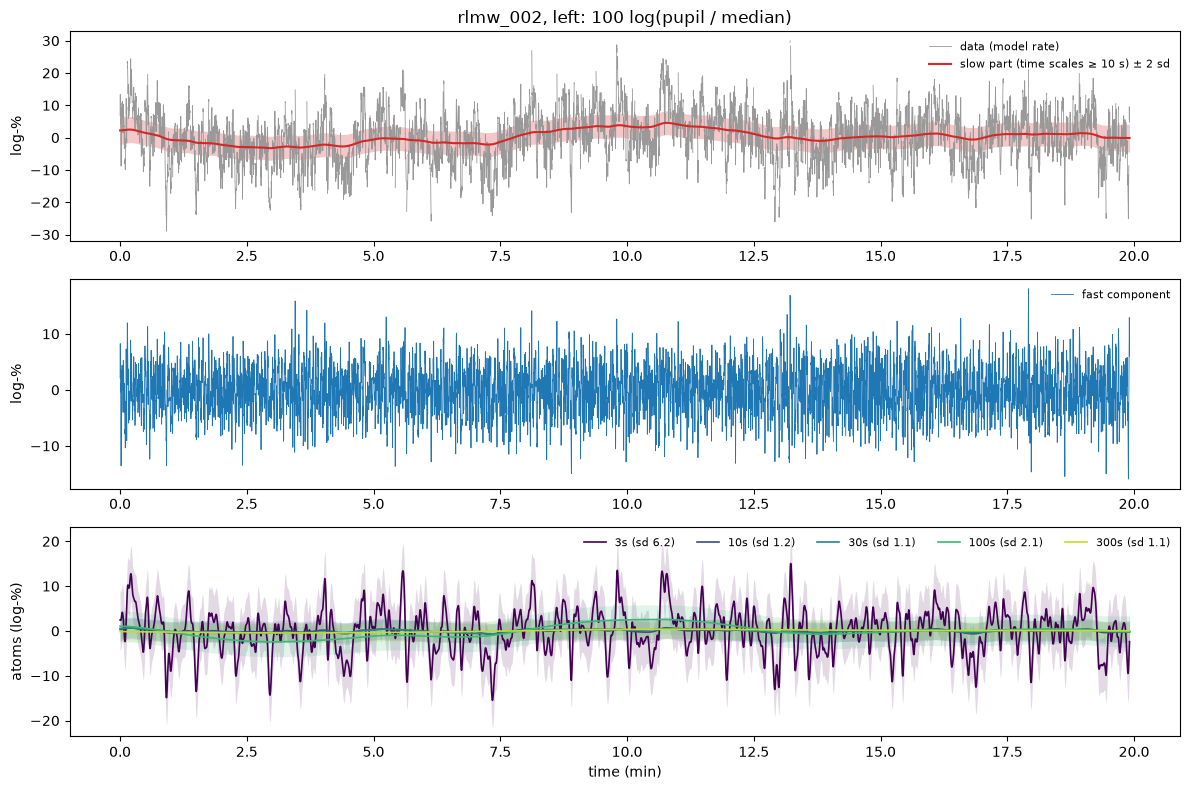

In [9]:
m.plot.decomposition();

Top: the data and the slow part (the mean plus all atoms with a time scale of at least 10 s) with two posterior standard deviations. Middle: the fast component. Bottom: the atoms.

How the variance is spread over the time scales:

total slow sd (time scales >= 10 s): {'left': 2.898439465891542}


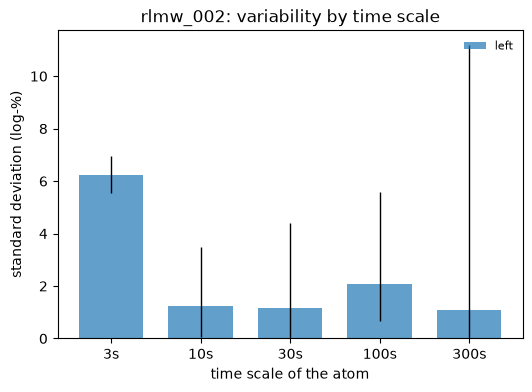

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
m.plot.timescales(ax=ax)
print("total slow sd (time scales >= 10 s):", m.slow_sd("10 s"))

The intervals of single atoms are wide. One recording of 20 minutes determines how much slow variance there is in total, but not well how it is divided between neighbouring atoms, which are a factor of 3 apart. For a single participant, interpret the slow time course and `slow_sd()`; the variances of single atoms are a matter for groups (see the end of this notebook).

The cut-off between "slow" and the rest can be chosen after the fit, because all atoms are estimated:

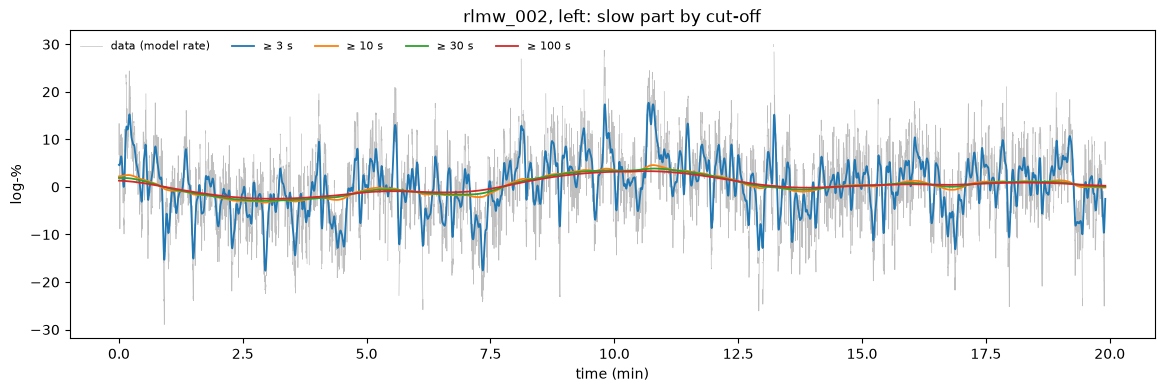

In [11]:
fig, ax = plt.subplots(figsize=(14, 4))
m.plot.slow(cutoffs=("3 s", "10 s", "30 s", "100 s"), ax=ax);

## Does the model describe the data?

The likelihood is made of predictions over 50 ms, so it is dominated by the fast dynamics. These checks look at the slow part too:

- **Variogram**: the typical size of a change of the signal over a lag, for the data and the model. With `check=True`, the band shows where the variograms of signals simulated from the fitted model (with the gaps of the data) fall.
- **Spectrum** of the data and of the model with its components.

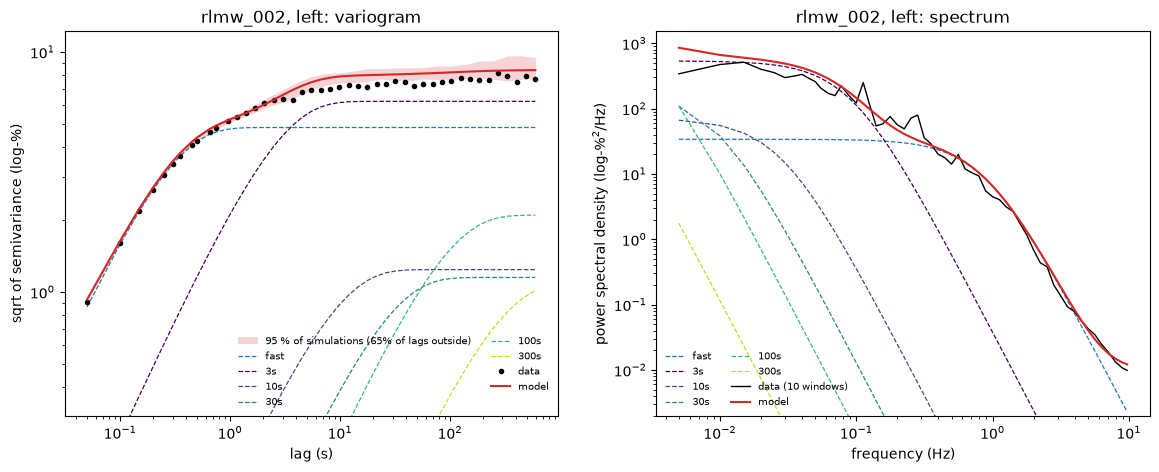

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
m.plot.variogram(check=True, ax=axs[0])
m.plot.spectrum(ax=axs[1]);

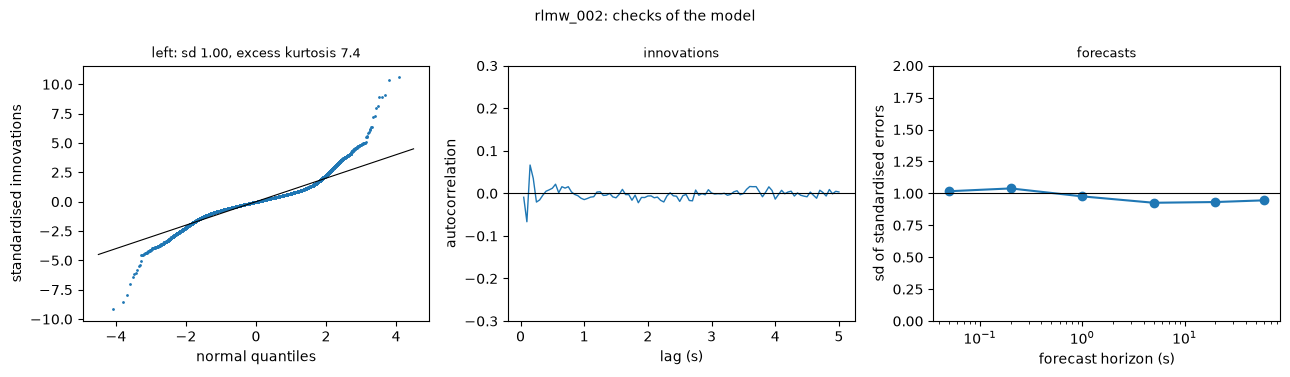

In [13]:
m.plot.diagnostics();

Left: the one-step prediction errors have heavier tails than a normal distribution (fast dilations and remaining artifacts). Middle: they are nearly uncorrelated. Right: forecasts over 50 ms to 60 s are calibrated if the standard deviation of their standardised errors is 1; below 1, the model expects more variability over that horizon than there is. The numbers behind the last panel:

In [14]:
m.forecast_calibration()

,eye,horizon,rmse,z_sd,n
0,left,0.05,1.102221,1.016607,1052
1,left,0.20,3.609661,1.038667,1016
2,left,1.00,6.334486,0.976470,935
3,left,5.00,7.539896,0.926334,930
4,left,20.00,7.787727,0.932058,915
5,left,60.00,8.018451,0.945363,885


In this recording the checks show a weakness: at lags above a few seconds, the variogram of the model lies above that of the data, and the forecasts over 5 s and more are a little too uncertain. The single fast component cannot describe the rise of the variogram between 0.3 and 3 s exactly; the likelihood, which is dominated by these short lags, makes up for it with a large 3-s atom, which then adds too much variance at longer lags. The section on comparing models below shows how to test another bank.

## Back to the original samples

The model works at 20 Hz in log-%, but its components are defined in continuous time. `predict()` evaluates them at the original samples and in the units of the data, also where the data are missing:

In [15]:
signal, lower, upper = m.predict("signal", interval=0.95)["left"]     # one value per sample of d
slow = m.predict("slow", cutoff="10 s")["left"]
len(d), signal.shape, slow.shape

(597301, (597301,), (597301,))

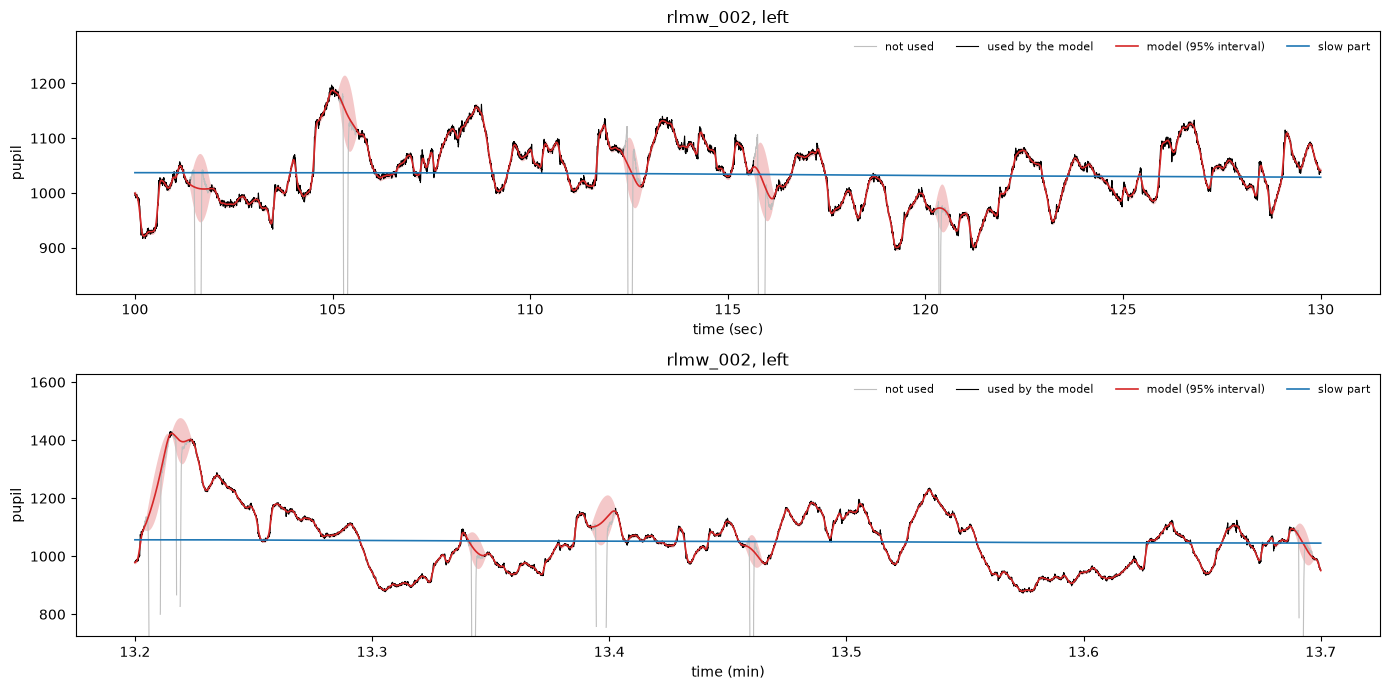

In [16]:
fig, axs = plt.subplots(2, 1, figsize=(14, 7))
m.plot.interpolation(plot_range=(100, 130), ax=axs[0])
m.plot.interpolation(plot_range=(13.2, 13.7), units="min", ax=axs[1])
fig.tight_layout()

Black: the samples the model used; grey: the samples it did not use (blinks with their margins); red: the expected signal with its 95 % interval, which opens up in the gaps; blue: the slow part.

`interpolate()` replaces all unusable samples of the recording by the expected signal and marks them as interpolated. It returns the `EyeData` object. Other than `d.pupil.blinks_interpolate()`, it uses one model for the whole recording and also bridges long gaps.

In [17]:
di = m.interpolate()
print("unusable samples before: %.1f %%, after: %.1f %%" % (
    100 * d.mask("left", "pupil").mean(), 100 * di.mask("left", "pupil").mean()))
di = m.store("slow", data=di)             # variable "pupilslow"
di = m.store("signal", data=di)           # the smoothed signal, "pupilsmooth"
di = m.store("detrended", data=di)        # signal minus slow part, "pupildetrended"
di.print_history()

unusable samples before: 4.5 %, after: 0.0 %


* rlmw_002
└ reset_time()
 └ pupil.blinks_detect()
  └ TimescaleModel.interpolate(eyes=['left'],store_as='pupil')
   └ TimescaleModel.store('slow',store_as='pupilslow',eyes=['left'],cutoff='10 s')
    └ TimescaleModel.store('signal',store_as='pupilsmooth',eyes=['left'],cutoff='10 s')
     └ TimescaleModel.store('detrended',store_as='pupildetrended',eyes=['left'],cutoff='10 s')


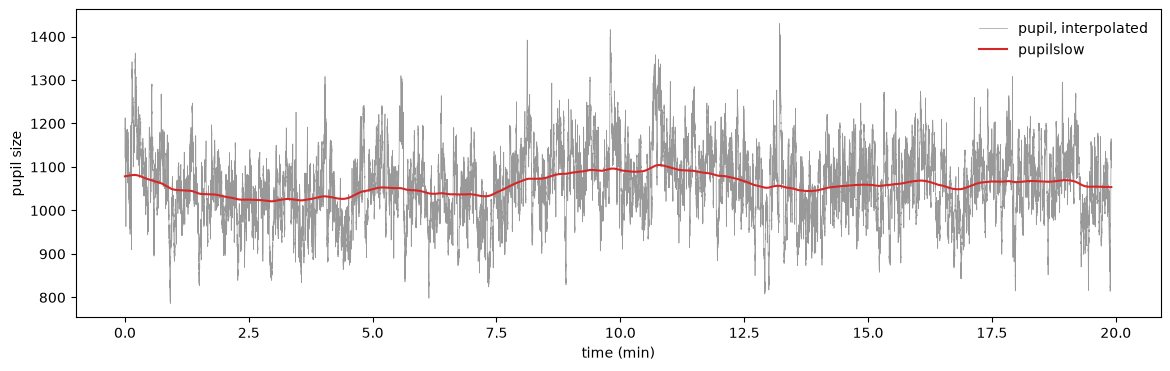

In [18]:
fig, ax = plt.subplots(figsize=(14, 4))
t = di.tx / 60000
ax.plot(t, di["left", "pupil"], color="0.6", lw=0.5, label="pupil, interpolated")
ax.plot(t, di["left", "pupilslow"], color="C3", lw=1.5, label="pupilslow")
ax.set(xlabel="time (min)", ylabel="pupil size")
ax.legend(frameon=False);

## Priors

A single recording cannot say much about an atom that carries little variance: the likelihood is flat towards zero variance. The fit therefore uses a prior on the parameters. The general priors describe how the parameters vary between recordings: they were derived from 155 recordings of four experiments (desk-mounted and portable EyeLink systems, tasks of 20 to 47 minutes). They come in three strengths:

- `"medium"` (default): the distribution over these recordings
- `"strong"`: half the standard deviations
- `"weak"`: twice the standard deviations

`prior=None` gives the maximum-likelihood fit, and a prior from your own group of recordings is described below. The fast component and the noise vary little between recordings, the variances of the atoms a lot, so even the medium prior is wide for the atoms: it mainly keeps them away from zero and from very large values. The priors are normal distributions on the log of the standard deviations and of the fast time scale, and on $u_k = \log(v_k + v_0)$ for the variance $v_k$ of atom $k$ (with $v_0 = 0.25$, so that an atom without variance has a finite value).

In [19]:
gm = pp.signal.gaussmarkov
gm.general_prior(strength="medium")

GaussianPrior(general, medium; mean ± sd)
  log_fast_sd             2.090 ± 0.360
  log_fast_ell            6.520 ± 0.300
  log_noise_sd           -1.680 ± 0.530
  u_3s                    2.420 ± 1.910
  u_10s                   3.240 ± 1.890
  u_30s                   1.460 ± 1.820
  u_100s                  1.610 ± 2.340
  u_300s                  2.620 ± 2.660

In [20]:
fits = {"medium": m}
for prior in ("weak", "strong", None):
    fits[str(prior)] = pp.TimescaleModel(d, eyes="left").fit(prior=prior)
pd.concat({k: v.summary().loc["left"] for k, v in fits.items()}, axis=1).round(2)

,medium,weak,strong,None
fast_sd,4.84,4.82,4.92,4.81
fast_ell,312.79,311.55,317.14,311.25
noise_sd,0.31,0.31,0.32,0.31
sd_3s,6.22,6.30,5.98,6.32
sd_10s,1.24,0.77,2.05,0.00
sd_30s,1.15,0.31,1.85,0.23
sd_100s,2.09,2.26,2.03,2.61
sd_300s,1.09,0.32,1.57,0.25
slow_sd,2.90,2.43,3.77,2.63
n_obs,21285.00,21285.00,21285.00,21285.00


The fast component and the noise are determined by the data and do not depend on the prior. The atoms do: without a prior, some atoms get no variance at all and their neighbours take it; the stronger the prior, the more evenly the slow variance is spread. The slow part of the signal changes little:

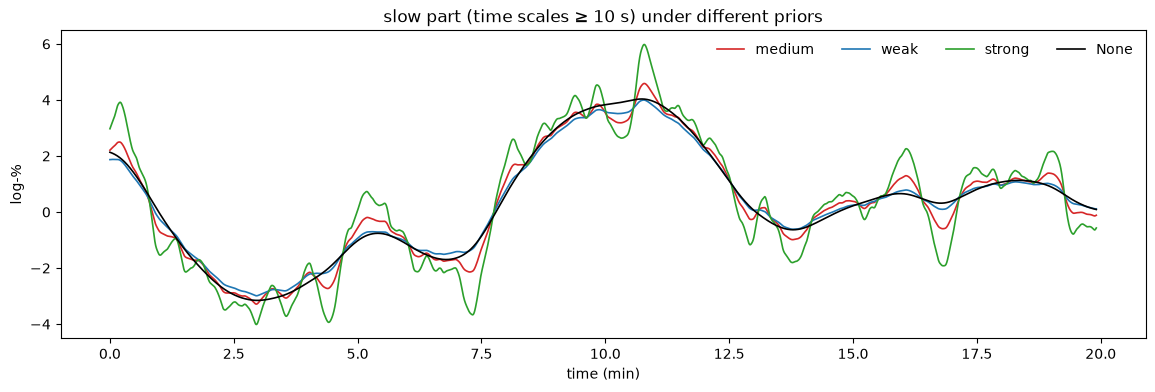

In [21]:
fig, ax = plt.subplots(figsize=(14, 4))
for (name, mod), color in zip(fits.items(), ("C3", "C0", "C2", "k")):
    ax.plot(mod.time / 60000, mod.components()["left"]["slow"][0], color=color, lw=1.2, label=name)
ax.set(xlabel="time (min)", ylabel="log-%", title="slow part (time scales ≥ 10 s) under different priors")
ax.legend(frameon=False, ncol=4);

## Comparing models: AIC, BIC and cross-validation

Models of the same data can be compared with `m.aic`, `m.bic` and `m.cross_validate()`. The cross-validation holds out blocks of one minute and scores how well they are predicted from the rest of the recording; a held-out minute has to be bridged by the slow components, so this score is more sensitive to them than the likelihood. `m.variogram_check()` gives the fraction of lags at which the variogram of the data is outside the range of the simulations.

The time scales of the atoms are an argument of the model. Here the default bank is compared with a bank that has one more atom at 1 s, and with a bank of three atoms a decade apart.

In [22]:
grids = {"3-300 s (default)": m,
         "1-300 s": pp.TimescaleModel(d, eyes="left", timescales=("1 s", "3 s", "10 s", "30 s", "100 s", "300 s")).fit(),
         "3, 30, 300 s": pp.TimescaleModel(d, eyes="left", timescales=("3 s", "30 s", "300 s")).fit()}
rows = {}
for name, mod in grids.items():
    rows[name] = dict(n_params=mod.fits["left"].n_params, loglik=mod.loglik["left"], aic=mod.aic["left"],
                      bic=mod.bic["left"], cv=mod.cross_validate(block="60 s")["left"],
                      slow_sd=mod.slow_sd("10 s")["left"],
                      variogram_outside=mod.variogram_check(rng=1)["left"].outside)
pd.DataFrame(rows).T.round(2)

,n_params,loglik,aic,bic,cv,slow_sd,variogram_outside
3-300 s (default),8.0,-32344.86,64705.72,64769.44,-32317.80,2.90,0.55
1-300 s,9.0,-32311.89,64641.79,64713.48,-32287.96,3.84,0.23
"3, 30, 300 s",6.0,-32345.02,64702.05,64749.84,-32318.23,2.96,0.58


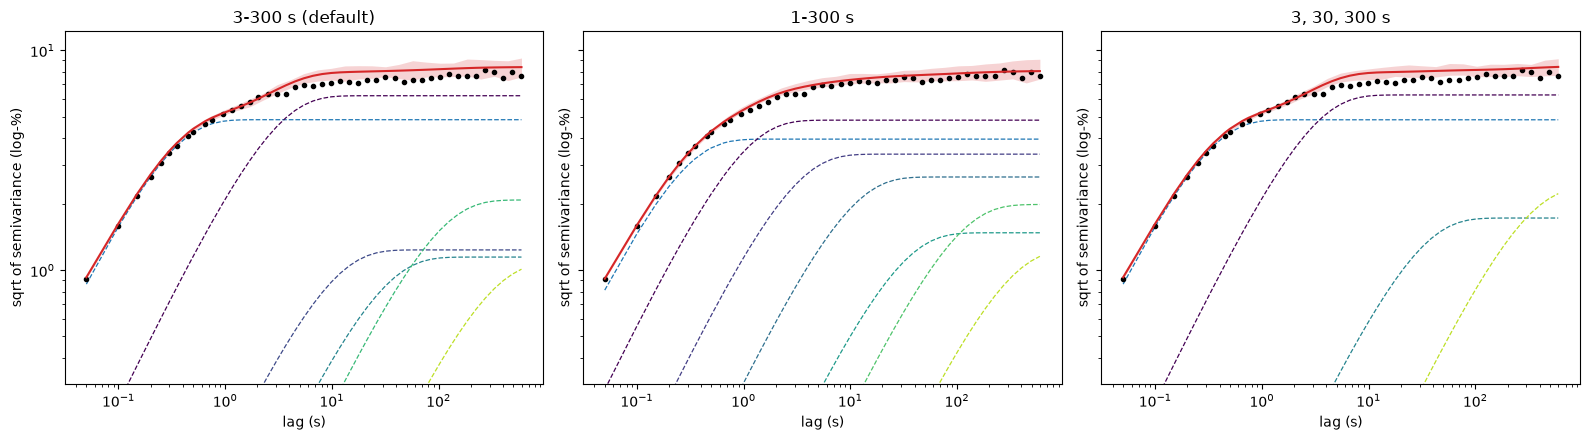

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, mod) in zip(axs, grids.items()):
    mod.plot.variogram(check=True, ax=ax)
    ax.set_title(name)
    ax.legend().remove()
fig.tight_layout()

Lower AIC and BIC and a higher cross-validation score are better. For this recording, the atom at 1 s improves the criteria and brings the variogram of the model back to the data. This recording is an exception, though: in 40 recordings of four experiments, the additional atom did not improve the AIC (median change +2). One recording is not enough to choose a structure; to do that for a study, sum the scores over its recordings and use the same structure for all of them, so that the parameters stay comparable.

## Segments

Many recordings consist of blocks with breaks, and the level of the pupil can differ between blocks. The model treats the periods that are not excluded as independent segments with a mean each. Exclude breaks with `d.exclude_intervals()` or keep the task with `d.keep_intervals()` (e.g., with intervals from `d.get_intervals()`); to split the data without excluding anything, pass `segments=` to the model.

As an illustration, we exclude a "break" of two minutes:

TimescaleModel('rlmw_002', eyes=['left'], timescales=(3s, 10s, 30s, 100s, 300s), 2 segment(s), 17.9 min at 20 Hz, valid: left 89%; fitted)


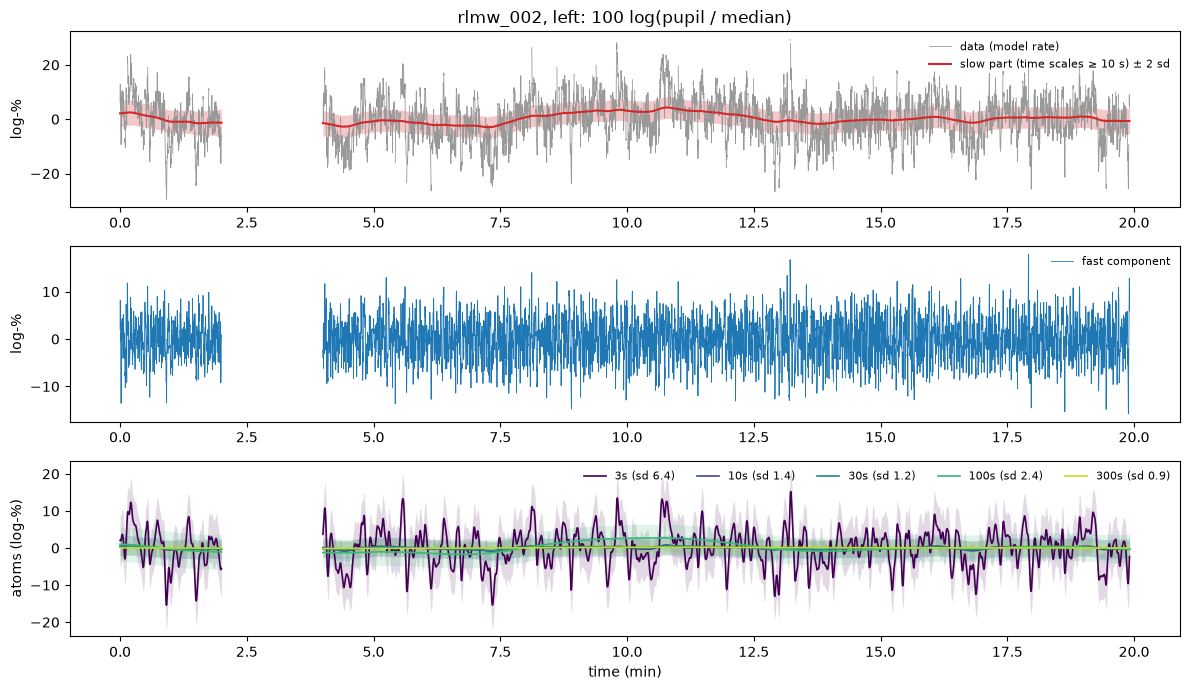

In [24]:
dseg = d.exclude_intervals([(2 * u.min, 4 * u.min)])
mseg = pp.TimescaleModel(dseg, eyes="left").fit()
print(mseg)
mseg.plot.decomposition(figsize=(12, 7));

Excluded periods are neither used nor reconstructed: `predict()` returns NaN there and `interpolate()` leaves them as they are.

## Both eyes

By default, each eye gets its own model:

In [25]:
m2 = pp.TimescaleModel(d).fit()
m2.summary().round(2)

,fast_sd,fast_ell,noise_sd,sd_3s,sd_10s,sd_30s,sd_100s,sd_300s,slow_sd,n_obs,loglik,aic,bic
left,4.84,312.79,0.31,6.22,1.24,1.15,2.09,1.09,2.90,21285,-32344.86,64705.72,64769.44
right,6.80,419.28,0.39,6.62,1.95,1.38,2.29,2.04,3.88,21580,-34218.47,68452.94,68516.78


With `binocular=True`, one model describes both eyes: the fast component and the atoms are common, each eye has its own mean and noise, and one more component describes the difference between the eyes (`diff_sd`, `diff_ell`). Where one eye is missing, the other one carries the reconstruction.

In [26]:
mb = pp.TimescaleModel(d, binocular=True).fit()
mb.summary().T.round(2)

,both
fast_sd,4.83
fast_ell,285.65
noise_sd_left,0.26
noise_sd_right,0.26
diff_sd,2.88
diff_ell,351.93
gain,1.09
sd_3s,8.52
sd_10s,1.03
sd_30s,0.56


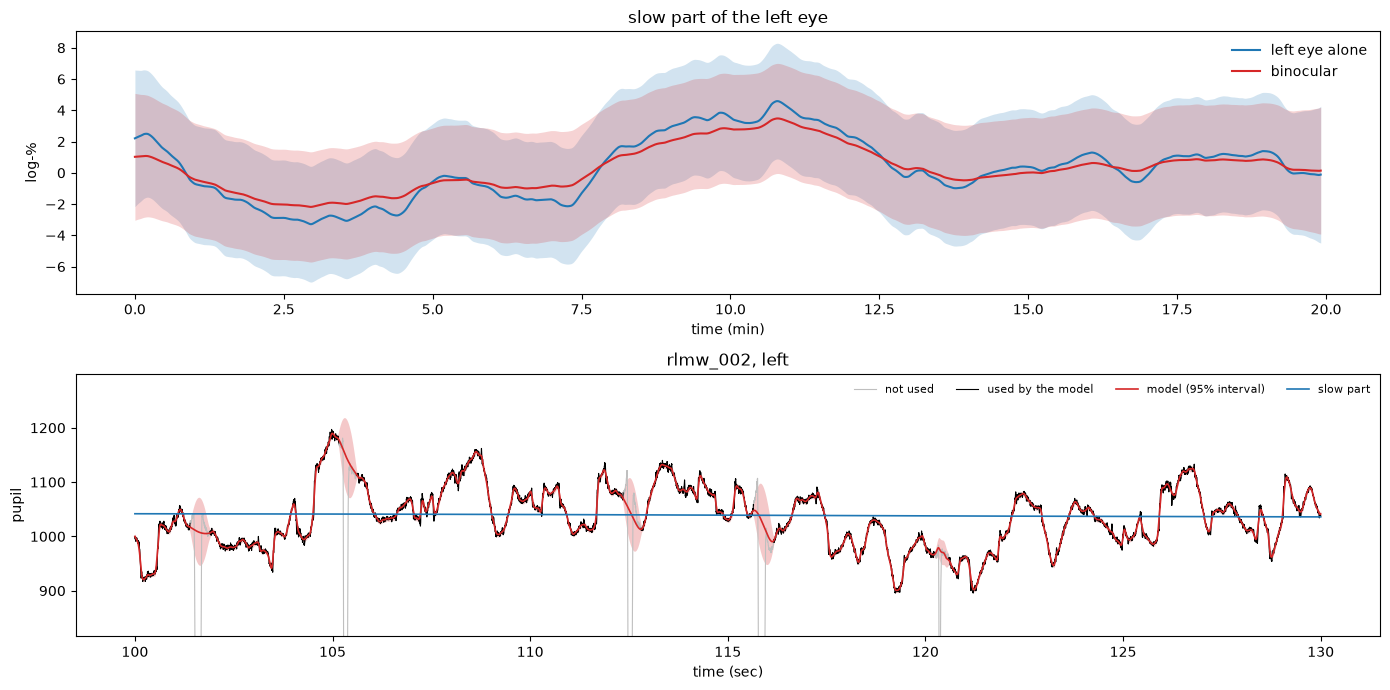

In [27]:
fig, axs = plt.subplots(2, 1, figsize=(14, 7))
for name, mod, color in (("left eye alone", m2, "C0"), ("binocular", mb, "C3")):
    mean, sd = mod.components("left")["left"]["slow"]
    axs[0].fill_between(mod.time / 60000, mean - 2 * sd, mean + 2 * sd, color=color, alpha=0.2, lw=0)
    axs[0].plot(mod.time / 60000, mean, color=color, label=name)
axs[0].set(xlabel="time (min)", ylabel="log-%", title="slow part of the left eye")
axs[0].legend(frameon=False)
mb.plot.interpolation(eye="left", plot_range=(100, 130), ax=axs[1])
fig.tight_layout()

## Simulating from the fitted model

`m.simulate()` draws a new recording from the fitted model: the latent pupil with the estimated parameters, scaled to the median of the recording, plus white noise of the estimated size. The result is a `SimEyeData` object, which holds the true components next to the data (see the [simulated data](../notebooks/simulation.ipynb) notebook). Comparing a simulation with the recording shows what the model captures, and fitting the model again to simulations shows how well its parameters can be recovered from a recording of this length:

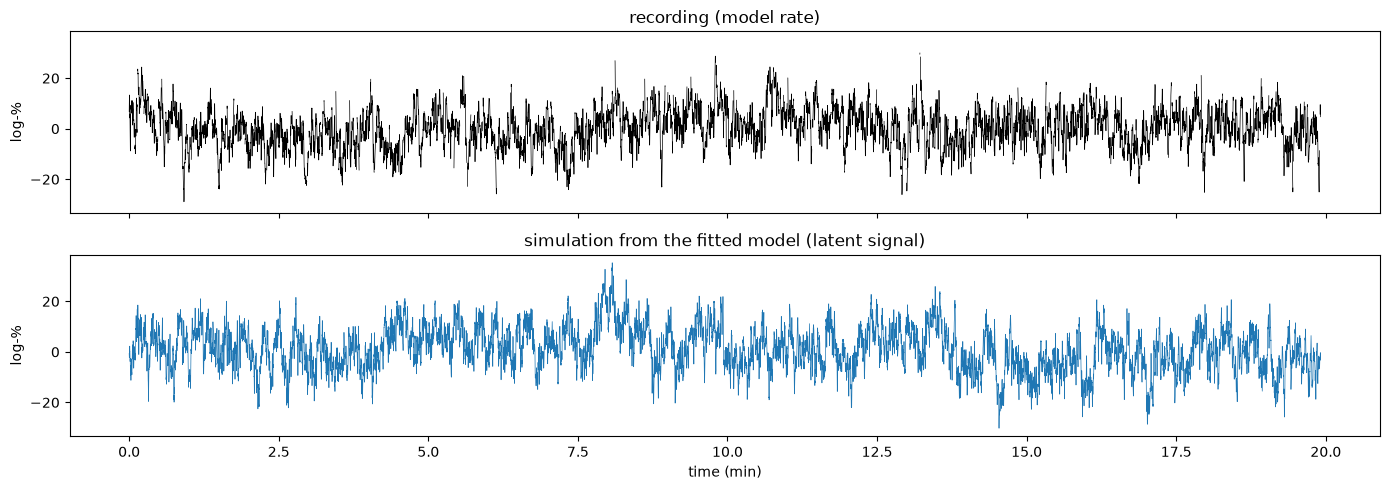

In [28]:
s = m.simulate(seed=1)
fig, axs = plt.subplots(2, 1, figsize=(14, 5), sharex=True, sharey=True)
axs[0].plot(m.time / 60000, m.y["left"], lw=0.5, color="k")
axs[0].set(ylabel="log-%", title="recording (model rate)")
axs[1].plot(s.tx / 60000, s.truth["left", "log_size"], lw=0.5, color="C0")
axs[1].set(xlabel="time (min)", ylabel="log-%", title="simulation from the fitted model (latent signal)")
fig.tight_layout()

In [29]:
refit = pd.DataFrame({seed: pp.TimescaleModel(m.simulate(seed=seed), eyes="left").fit(hessian=False).params["left"]
                      for seed in range(5)})
pd.DataFrame({"fitted to the recording": m.params["left"],
              "refit to 5 simulations: median": refit.median(axis=1),
              "min": refit.min(axis=1), "max": refit.max(axis=1)}).round(2)

,fitted to the recording,refit to 5 simulations: median,min,max
fast_sd,4.84,4.85,4.69,4.93
fast_ell,312.79,314.46,307.51,319.73
noise_sd,0.31,0.32,0.32,0.32
sd_3s,6.22,5.95,5.71,6.51
sd_10s,1.24,2.74,1.71,3.32
sd_30s,1.15,1.31,0.39,2.62
sd_100s,2.09,1.51,0.92,2.85
sd_300s,1.09,1.64,0.77,3.30


The fast component and the noise come back closely; the standard deviations of single atoms vary between simulations of the same model, as their wide intervals above suggest.

## Groups of recordings

For a study, `pp.TimescaleGroup` estimates the models of all recordings together. The parameters of the recordings are treated as draws from a group distribution, whose mean and spread are estimated with them (empirical Bayes). The group mean is the typical mix of time scales; the estimate of each recording is shrunk towards it where the recording itself is uninformative.

The group takes a dict (or list) of `EyeData` objects or of `TimescaleModel` objects. `pp.TimescaleGroup.from_files(files, preprocess=...)` reads the files one at a time, so that only the reduced data stay in memory.

The example datasets of the package only contain three recordings, so the following shows the mechanics only: a group should have many more members, and they should be recordings of the same kind. We use both eyes of the three recordings as six members (20 minutes each). The n-back recording is used as it is, with the breaks between its blocks, which gives it far more slow variance than the other two.

In [30]:
recordings = {"rlmw_002": d,
              "rlmw_010": pp.get_example_data("rlmw_010_edf").pupil.blinks_detect(),
              "nback_001": pp.get_example_data("nback_001").crop(0, 20, units="min").pupil.blinks_detect()}
g = pp.TimescaleGroup(recordings)
g

TimescaleGroup(3 recordings, 6 members, TimescaleBank(timescales=(3s, 10s, 30s, 100s, 300s), nu=1.5, v0=0.25); not fitted)

In [31]:
%time g.fit(n_iter=3)
print("converged:", g.group.converged)
g.group_summary().round(2)

CPU times: user 59.1 ms, sys: 32 ms, total: 91.1 ms
Wall time: 1min 18s
converged: False


,parameter,mean,sd,typical,low,high
fast_sd,log_fast_sd,1.72,0.10,5.59,5.03,6.20
fast_ell,log_fast_ell,5.86,0.16,352.11,298.73,415.02
noise_sd,log_noise_sd,-0.92,0.15,0.40,0.34,0.46
sd_3s,u_3s,3.54,0.54,5.84,4.44,7.67
sd_10s,u_10s,-0.06,0.52,0.83,0.56,1.15
sd_30s,u_30s,2.01,2.31,2.69,0.70,8.69
sd_100s,u_100s,2.80,2.15,4.02,1.29,11.83
sd_300s,u_300s,1.96,1.64,2.62,1.06,6.04


`mean` and `sd` describe the group distribution of the entries of the parameter vector (logs); `typical`, `low` and `high` are the group mean and the mean minus/plus one standard deviation on the natural scale (standard deviations in log-%, `fast_ell` in ms).

After the three iterations used here, the group mean was still changing (`g.group.converged` is False); with real data, use more iterations (`n_iter`) and check that it is True.

In [32]:
g.summary().round(2)

fast_sd  fast_ell  noise_sd  sd_3s  sd_10s  sd_30s  sd_100s  \
recording unit                                                                 
rlmw_002  left      4.85    313.76      0.32   6.21    0.80    1.06     2.23   
          right     6.70    414.36      0.39   6.83    0.81    1.54     2.62   
rlmw_010  left      5.79    277.08      0.37   4.14    0.84    1.29     1.71   
          right     5.24    319.30      0.49   3.98    0.84    1.11     1.90   
nback_001 left      5.31    378.24      0.47   7.84    0.85   11.37    13.96   
          right     5.79    438.03      0.39   7.19    0.85   11.61    14.82   

                 sd_300s  slow_sd  n_obs    loglik  
recording unit                                      
rlmw_002  left      1.81     3.17  21285 -32344.63  
          right     1.50     3.48  21580 -34218.17  
rlmw_010  left      5.58     6.04  20343 -36453.93  
          right     5.84     6.30  20350 -34760.75  
nback_001 left      1.84    18.12  17715 -28903.84  
          right     1.86    18.94  17675 -26605.75

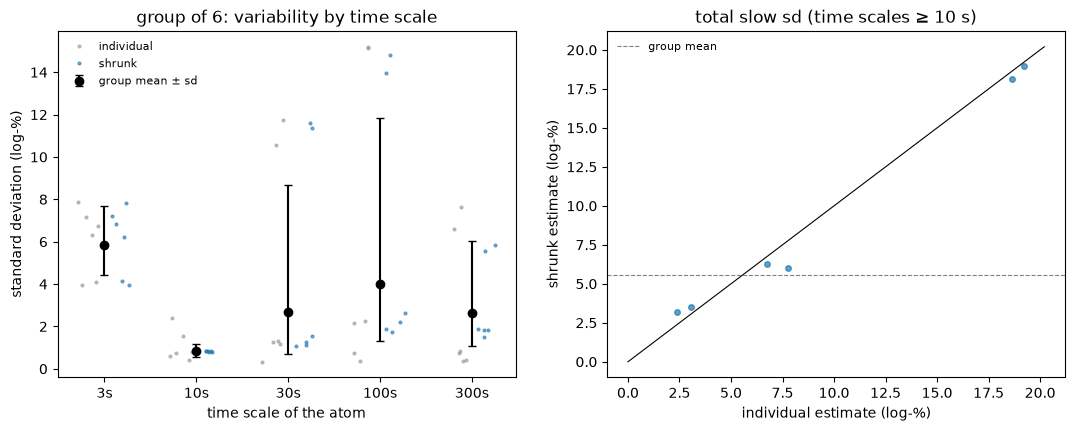

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
g.plot.params(ax=axs[0])
g.plot.shrinkage(ax=axs[1]);

The models of the group are ordinary `TimescaleModel` objects with the shrunk estimates (the estimates without pooling are kept in `model.individual`):

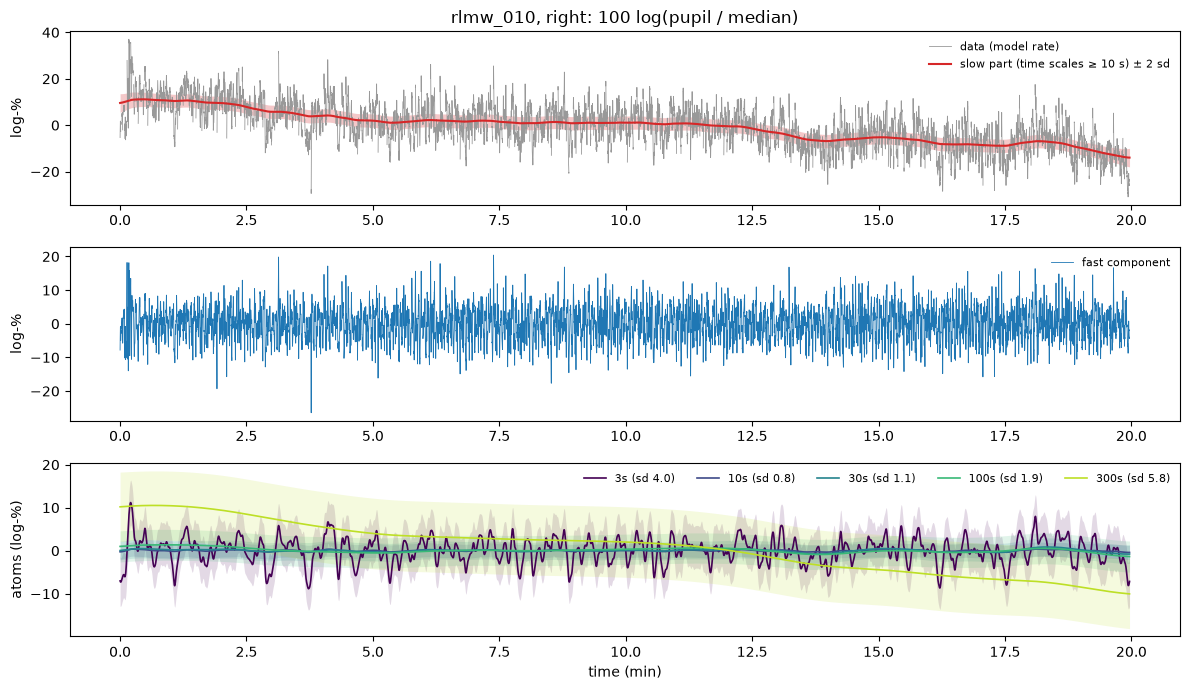

In [34]:
g.models["rlmw_010"].plot.decomposition(eye="right", figsize=(12, 7));

The group distribution can be used as the prior of other recordings of the same kind:

```python
new = pp.TimescaleModel(d_new).fit(prior=g.prior)
```

## Summary of the API

```python
m = pp.TimescaleModel(d, eyes=[], binocular=False, timescales=..., segments=None)
m.fit(prior="medium")                 # "weak" | "medium" | "strong" | GaussianPrior | None
m.summary(); m.params; m.slow_sd("10 s"); m.loglik; m.aic; m.bic
m.cross_validate(); m.forecast_calibration(); m.variogram_check()
m.components()                        # smoothed parts at the rate of the model (log-%)
m.predict("signal" | "slow" | "detrended" | <component>, interval=0.95)   # original samples and units
d = m.interpolate(); d = m.store("slow")
m.plot.decomposition(); m.plot.slow(); m.plot.timescales(); m.plot.variogram()
m.plot.spectrum(); m.plot.diagnostics(); m.plot.interpolation()

g = pp.TimescaleGroup(recordings).fit()
g.group_summary(); g.summary(); g.prior; g.models[name]; g.plot.params(); g.plot.shrinkage()
```

The functions behind these classes work on plain arrays and are in `pp.signal.gaussmarkov` (`TimescaleBank`, `fit_bank`, `fit_group`, ...).